# Life Expectancy Classification Project

## Overview
This project formulates a **multiclass classification problem** using the World Health Organization (WHO) Life Expectancy dataset.
The objective is to classify countries into three life expectancy tiers:
- **`Low`**: <= 60 years
- **`Medium`**: 60 - 75 years
- **`High`**: > 75 years

### Workflow Pipeline:
1. **Data Ingestion & Target Discretization**: Load dataset and bin continuous life expectancy into categorical tiers.
2. **Exploratory Data Analysis (EDA)**: Inspect distributions, types, summary statistics, and missing data.
3. **Data Cleaning & Preprocessing**: Clean column names, drop redundant features, and handle missing target entries.
4. **Correlation Analysis**: Identify influential demographic and health indicators correlated with life expectancy.
5. **Stratified Train-Test Split**: Partition data while maintaining class balance.
6. **Pipeline Architecture**:
   - Numerical Imputation (`KNNImputer`)
   - Categorical Imputation & Encoding (`SimpleImputer` + `OneHotEncoder`)
   - Feature Selection (`RFE` with Decision Tree)
   - Final Classifier (`DecisionTreeClassifier`)
7. **Model Evaluation & Hyperparameter Optimization (`GridSearchCV`)**: Tune parameters with 5-fold cross-validation and evaluate using classification reports and confusion matrices.

## 1. Import Libraries
Import data manipulation, preprocessing, pipeline, model selection, and evaluation modules.

In [1]:
# ==============================================================================
# STEP 1: IMPORT REQUIRED LIBRARIES
# ==============================================================================

# Core libraries for data analysis and numerical computations
import pandas as pd
import numpy as np

# Data visualization libraries
import seaborn as sns
import matplotlib.pyplot as plt

# Scikit-Learn: Machine Learning Model
from sklearn.tree import DecisionTreeClassifier

# Scikit-Learn: Imputation strategies for missing values
from sklearn.impute import KNNImputer, SimpleImputer

# Scikit-Learn: Feature preprocessing and encoding
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler

# Scikit-Learn: Pipeline assembly and column transformation
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Scikit-Learn: Feature selection
from sklearn.feature_selection import RFE

# Scikit-Learn: Model selection, cross-validation, and performance evaluation
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 2. Data Loading & Target Discretization
Load the raw WHO dataset and bin the continuous `Life expectancy ` variable into three classes: `Low` (<= 60), `Medium` (60 - 75), and `High` (> 75).

In [2]:
# ==============================================================================
# STEP 2: LOAD DATASET
# ==============================================================================
# Read the WHO Life Expectancy CSV data into a pandas DataFrame
df = pd.read_csv("Life Expectancy Data.csv")

In [3]:
# ==============================================================================
# STEP 3: DISCRETIZE TARGET VARIABLE (LIFE EXPECTANCY)
# ==============================================================================
# Bin the continuous 'Life expectancy ' variable into three discrete categories:
# - 'Low'    : (0, 60] years
# - 'Medium' : (60, 75] years
# - 'High'   : (75, 100] years
df['Life_Expectancy_Category '] = pd.cut(
    df['Life expectancy '],
    bins=[0, 60, 75, 100],
    labels=['Low', 'Medium', 'High']
)

## 3. Exploratory Data Analysis (EDA)
Inspect column names, first/last rows, data types, statistical distributions, and missing values across features.

In [4]:
# List all original column names (note trailing spaces present in raw headers)
df.columns

Index(['Country', 'Year', 'Status', 'Life expectancy ', 'Adult Mortality',
       'infant deaths', 'Alcohol', 'percentage expenditure', 'Hepatitis B',
       'Measles ', ' BMI ', 'under-five deaths ', 'Polio', 'Total expenditure',
       'Diphtheria ', ' HIV/AIDS', 'GDP', 'Population',
       ' thinness  1-19 years', ' thinness 5-9 years',
       'Income composition of resources', 'Schooling',
       'Life_Expectancy_Category '],
      dtype='str')

In [5]:
# Preview the first 5 records of the dataset
df.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Life_Expectancy_Category
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1,Medium
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0,Low
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9,Low
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8,Low
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5,Low


In [6]:
# Preview the last 5 records of the dataset
df.tail()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Life_Expectancy_Category
2933,Zimbabwe,2004,Developing,44.3,723.0,27,4.36,0.0,68.0,31,...,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2,Low
2934,Zimbabwe,2003,Developing,44.5,715.0,26,4.06,0.0,7.0,998,...,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5,Low
2935,Zimbabwe,2002,Developing,44.8,73.0,25,4.43,0.0,73.0,304,...,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0,Low
2936,Zimbabwe,2001,Developing,45.3,686.0,25,1.72,0.0,76.0,529,...,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8,Low
2937,Zimbabwe,2000,Developing,46.0,665.0,24,1.68,0.0,79.0,1483,...,7.10,78.0,43.5,547.358878,12222251.0,11.0,11.2,0.434,9.8,Low


In [7]:
# Display concise summary of the DataFrame: column data types, non-null counts, and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype   
---  ------                           --------------  -----   
 0   Country                          2938 non-null   str     
 1   Year                             2938 non-null   int64   
 2   Status                           2938 non-null   str     
 3   Life expectancy                  2928 non-null   float64 
 4   Adult Mortality                  2928 non-null   float64 
 5   infant deaths                    2938 non-null   int64   
 6   Alcohol                          2744 non-null   float64 
 7   percentage expenditure           2938 non-null   float64 
 8   Hepatitis B                      2385 non-null   float64 
 9   Measles                          2938 non-null   int64   
 10   BMI                             2904 non-null   float64 
 11  under-five deaths                2938 non-null   int64   
 12  Polio            

In [8]:
# Statistical summary for categorical variables ('Country' and 'Status')
df.describe(include='object')

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_11592\618092479.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,Country,Status
count,2938,2938
unique,193,2
top,Afghanistan,Developing
freq,16,2426


In [9]:
# Statistical summary for all numerical features (count, mean, std, min, 25%, 50%, 75%, max)
df.describe()

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2938.000000,2928.000000,2928.000000,2938.000000,2744.000000,2938.000000,2385.000000,2938.000000,2904.000000,2938.000000,2919.000000,2712.00000,2919.000000,2938.000000,2490.000000,2.286000e+03,2904.000000,2904.000000,2771.000000,2775.000000
mean,2007.518720,69.224932,164.796448,30.303948,4.602861,738.251295,80.940461,2419.592240,38.321247,42.035739,82.550188,5.93819,82.324084,1.742103,7483.158469,1.275338e+07,4.839704,4.870317,0.627551,11.992793
std,4.613841,9.523867,124.292079,117.926501,4.052413,1987.914858,25.070016,11467.272489,20.044034,160.445548,23.428046,2.49832,23.716912,5.077785,14270.169342,6.101210e+07,4.420195,4.508882,0.210904,3.358920
min,2000.000000,36.300000,1.000000,0.000000,0.010000,0.000000,1.000000,0.000000,1.000000,0.000000,3.000000,0.37000,2.000000,0.100000,1.681350,3.400000e+01,0.100000,0.100000,0.000000,0.000000
25%,2004.000000,63.100000,74.000000,0.000000,0.877500,4.685343,77.000000,0.000000,19.300000,0.000000,78.000000,4.26000,78.000000,0.100000,463.935626,1.957932e+05,1.600000,1.500000,0.493000,10.100000
50%,2008.000000,72.100000,144.000000,3.000000,3.755000,64.912906,92.000000,17.000000,43.500000,4.000000,93.000000,5.75500,93.000000,0.100000,1766.947595,1.386542e+06,3.300000,3.300000,0.677000,12.300000
75%,2012.000000,75.700000,228.000000,22.000000,7.702500,441.534144,97.000000,360.250000,56.200000,28.000000,97.000000,7.49250,97.000000,0.800000,5910.806335,7.420359e+06,7.200000,7.200000,0.779000,14.300000
max,2015.000000,89.000000,723.000000,1800.000000,17.870000,19479.911610,99.000000,212183.000000,87.300000,2500.000000,99.000000,17.60000,99.000000,50.600000,119172.741800,1.293859e+09,27.700000,28.600000,0.948000,20.700000


In [10]:
# Compute the total number of missing (null) values in each column, ordered descending
df.isnull().sum().sort_values(ascending=False)

Population                         652
Hepatitis B                        553
GDP                                448
Total expenditure                  226
Alcohol                            194
Income composition of resources    167
Schooling                          163
 thinness  1-19 years               34
 thinness 5-9 years                 34
 BMI                                34
Polio                               19
Diphtheria                          19
Life expectancy                     10
Adult Mortality                     10
Life_Expectancy_Category            10
infant deaths                        0
Country                              0
Year                                 0
Status                               0
under-five deaths                    0
Measles                              0
percentage expenditure               0
 HIV/AIDS                            0
dtype: int64

## 4. Data Cleaning & Feature Preparation
Standardize column headers (lower snake_case), check for duplicate rows, inspect cardinality, calculate missing value percentages, and drop redundant columns like `schooling`.

In [11]:
# ==============================================================================
# STEP 4: DATA CLEANING & COLUMN STANDARDIZATION
# ==============================================================================
# Standardize column names by:
# 1. Stripping leading and trailing whitespaces
# 2. Converting all characters to lowercase
# 3. Replacing whitespace with underscores
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

In [12]:
# Verify duplicate rows across the entire dataset (0 duplicates found)
df.duplicated().sum()

np.int64(0)

In [13]:
# Inspect the number of unique distinct values per column
df.nunique().sort_values

<bound method Series.sort_values of country                             193
year                                 16
status                                2
life_expectancy                     362
adult_mortality                     425
infant_deaths                       209
alcohol                            1076
percentage_expenditure             2328
hepatitis_b                          87
measles                             958
bmi                                 608
under-five_deaths                   252
polio                                73
total_expenditure                   818
diphtheria                           81
hiv/aids                            200
gdp                                2490
population                         2278
thinness__1-19_years                200
thinness_5-9_years                  207
income_composition_of_resources     625
schooling                           173
life_expectancy_category              3
dtype: int64>

In [14]:
# Build a summary DataFrame showing both raw count and percentage of missing values
missing = pd.DataFrame({
    'Missing' : df.isnull().sum(),
    'Percentage' : df.isnull().mean() * 100
})

# Display missing data sorted from highest percentage to lowest
missing.sort_values(
    by='Percentage',
    ascending=False
)

,Missing,Percentage
population,652,22.191967
hepatitis_b,553,18.822328
gdp,448,15.248468
total_expenditure,226,7.692308
alcohol,194,6.603131
income_composition_of_resources,167,5.684139
schooling,163,5.547992
thinness__1-19_years,34,1.157250
thinness_5-9_years,34,1.157250
bmi,34,1.157250


In [15]:
# Drop 'schooling' column due to high multicollinearity and potential data redundancy
df = df.drop(columns='schooling')

In [16]:
# Confirm duplicate count remains 0 after dropping 'schooling'
df.duplicated().sum()

np.int64(0)

In [17]:
# Re-check null value counts across remaining columns
df.isnull().sum()

country                              0
year                                 0
status                               0
life_expectancy                     10
adult_mortality                     10
infant_deaths                        0
alcohol                            194
percentage_expenditure               0
hepatitis_b                        553
measles                              0
bmi                                 34
under-five_deaths                    0
polio                               19
total_expenditure                  226
diphtheria                          19
hiv/aids                             0
gdp                                448
population                         652
thinness__1-19_years                34
thinness_5-9_years                  34
income_composition_of_resources    167
life_expectancy_category            10
dtype: int64

## 5. Correlation Analysis
Encode the ordinal categories (`Low`: 0, `Medium`: 1, `High`: 2) to evaluate Pearson correlation with numerical features, revealing top positively and negatively associated variables.

In [31]:
# ==============================================================================
# STEP 5: CORRELATION ANALYSIS WITH TARGET
# ==============================================================================
from sklearn.preprocessing import OrdinalEncoder

# Temporarily map categories: Low -> 0, Medium -> 1, High -> 2 to compute correlations
encoder = OrdinalEncoder(
    categories=[['Low', 'Medium', 'High']]
)

df['life_expectancy_encoded'] = encoder.fit_transform(
    df[['life_expectancy_category']]
)

# Calculate Pearson correlation of numerical features against the target tier
corr = df.corr(numeric_only=True)['life_expectancy_encoded']

# Print correlations sorted descending
print(corr.sort_values(ascending=False))

# Key Positive Correlations:
# - life_expectancy                 : 0.894274
# - income_composition_of_resources : 0.676540
# - bmi                             : 0.516914
# - gdp                             : 0.470781
# - diphtheria                      : 0.427442
# - polio                           : 0.415068
# - alcohol                         : 0.402944
# - percentage_expenditure          : 0.389899

life_expectancy_encoded            1.000000
life_expectancy                    0.894274
income_composition_of_resources    0.676540
bmi                                0.516914
gdp                                0.470781
diphtheria                         0.427442
polio                              0.415068
alcohol                            0.402944
percentage_expenditure             0.389899
total_expenditure                  0.231913
hepatitis_b                        0.203713
year                               0.148432
population                        -0.006384
measles                           -0.145250
infant_deaths                     -0.156486
under-five_deaths                 -0.178731
thinness_5-9_years                -0.441804
thinness__1-19_years              -0.448756
hiv/aids                          -0.452541
adult_mortality                   -0.633283
Name: life_expectancy_encoded, dtype: float64


## 6. Target Imputation & Train-Test Split
Impute missing target entries with the mode, separate predictors X from target y (preventing data leakage by dropping both continuous and categorical targets from X), and perform a stratified 80/20 train-test split.

In [30]:
# Impute the 10 missing entries in 'life_expectancy_category' using the mode ('Medium')
df['life_expectancy_category'] = df['life_expectancy_category'].fillna(df['life_expectancy_category'].mode()[0])

In [32]:
# ==============================================================================
# STEP 6: TRAIN-TEST SPLIT
# ==============================================================================
# Separate features (X) and target (y):
# Drop 'life_expectancy_category' (target) and 'life_expectancy' (continuous target) to prevent leakage
X = df.drop(columns=['life_expectancy_category', 'life_expectancy'])

y = df['life_expectancy_category']

# Perform 80% train / 20% test stratified split to maintain class distributions
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [33]:
# Encode categorical labels to integers if needed (scikit-learn accepts string labels as well)
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

## 7. Feature Grouping & Pipeline Construction
Define categorical and numerical feature sets, build dedicated preprocessing pipelines (`KNNImputer` for numerical, `SimpleImputer` + `OneHotEncoder` for categorical), and combine them with a `ColumnTransformer`.

In [34]:
# (Exploratory feature subset tested during experimentation):
# cat_cols = []
# num_cols = ['income_composition_of_resources', 'bmi', 'gdp', 'diphtheria', 'polio', 'alcohol', 'percentage_expenditure', 'total_expenditure', 'adult_mortality', 'hiv/aids', 'thinness_5-9_years', 'thinness__1-19_years']

In [35]:
# Categorical columns requiring imputation and one-hot encoding
cat_cols = ['status', 'country']

# Numerical columns requiring KNN-based missing value imputation
num_cols = [
    'year', 'adult_mortality', 'infant_deaths', 'alcohol', 
    'percentage_expenditure', 'hepatitis_b', 'measles', 'bmi', 
    'under-five_deaths', 'polio', 'total_expenditure', 'diphtheria', 
    'hiv/aids', 'gdp', 'population', 'thinness__1-19_years', 
    'thinness_5-9_years', 'income_composition_of_resources'
]

## 8. Feature Selection via Recursive Feature Elimination (RFE)
Configure RFE using a `DecisionTreeClassifier` estimator to dynamically select the top 5 most informative features.

In [36]:
# ==============================================================================
# STEP 7: RECURSIVE FEATURE ELIMINATION (RFE)
# ==============================================================================
# Initialize RFE with a DecisionTreeClassifier to recursively select the top 5 features
rfe = RFE(
    estimator=DecisionTreeClassifier(
        max_depth=10,
        class_weight=None,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=20
    ),
    n_features_to_select=5,
    step=1
)

In [37]:
# ==============================================================================
# STEP 8: PREPROCESSING PIPELINES & COMPLETE MODEL PIPELINE
# ==============================================================================

# Pipeline for numerical features: impute missing values using KNN (k=5)
num_pipline = Pipeline([
    ('imputer', KNNImputer(n_neighbors=5))
])

# Pipeline for categorical features: impute using most frequent value, then one-hot encode
cat_pipline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine numerical and categorical transformers
preprocess = ColumnTransformer([
    ('cat', cat_pipline, cat_cols),
    ('num', num_pipline, num_cols)
])

# Assemble complete end-to-end Pipeline: Preprocessing -> Feature Selection -> Classifier
model = Pipeline([
    ('preprocess', preprocess),
    ('features', rfe),
    ('model', DecisionTreeClassifier(
        max_depth=10,
        class_weight=None,
        criterion='gini',
        min_samples_leaf=1,
        min_samples_split=5
    ))
])

## 9. Model Training & Evaluation
Fit the full pipeline (Preprocessing -> RFE -> Decision Tree) on the training set, generate predictions on the test set, and evaluate performance using precision, recall, F1-score, and a confusion matrix.

In [38]:
# Best parameters identified from GridSearchCV tuning:
# Best parameters: {'features__n_features_to_select': 5, 'model__class_weight': None, 'model__criterion': 'gini', 'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5}
# Best CV score (Macro F1): 0.91113826713461

In [39]:
# ==============================================================================
# STEP 9: FIT MODEL ON TRAINING DATA
# ==============================================================================
# Train the entire pipeline (imputation, encoding, RFE feature selection, and decision tree)
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('features', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['country','year','status',...,'thinness_5-9_years', 'income_composition_of_resources','life_expectancy_encoded']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (def

In [40]:
# ==============================================================================
# STEP 10: MODEL EVALUATION ON UNSEEN TEST DATA
# ==============================================================================
# Generate predictions on the holdout test set
y_pred = model.predict(X_test)

In [41]:
# Generate and print classification metrics: precision, recall, f1-score, and support per class
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

        High       0.85      0.90      0.87       165
         Low       0.95      0.90      0.92       119
      Medium       0.90      0.89      0.90       304

    accuracy                           0.90       588
   macro avg       0.90      0.90      0.90       588
weighted avg       0.90      0.90      0.90       588



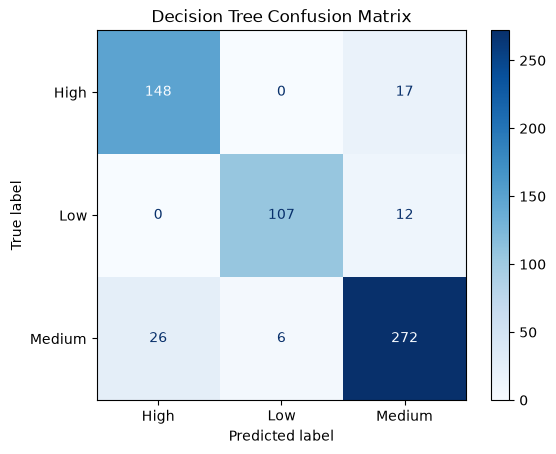

In [42]:
# Plot confusion matrix to inspect correct vs. misclassified counts for Low, Medium, High tiers
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(
    model,
    X_test,
    y_test,
    cmap='Blues'
)

plt.title('Decision Tree Confusion Matrix')
plt.show()

## 10. Hyperparameter Optimization (`GridSearchCV`)
Perform exhaustive grid search over decision tree depth, splitting criteria, minimum samples, class weighting, and number of RFE features using 5-fold cross-validation with Macro F1 scoring.

In [45]:
# ==============================================================================
# STEP 11: HYPERPARAMETER TUNING VIA GRIDSEARCHCV
# ==============================================================================
# Define hyperparameter grid for DecisionTreeClassifier and RFE selection
param_grid = {
    'model__max_depth': [3, 5, 7, 10, None],
    'model__min_samples_split': [2, 5, 10, 20],
    'model__min_samples_leaf': [1, 2, 5, 10],
    'model__criterion': ['gini', 'entropy', 'log_loss'],
    'model__class_weight': [None, 'balanced'], 
    'features__n_features_to_select' : [5, 8, 10, 12, 15, 18, 20]
}

# 5-fold cross-validation optimizing Macro F1 score
grid = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1
)

# Run hyperparameter search on the training data
grid.fit(X_train, y_train)

# Display the optimal parameter combination and resulting score
print("Best parameters:", grid.best_params_)
print("Best CV score:", grid.best_score_)

KeyboardInterrupt: 